# TweetEval – Offensive Language Detection
## Notebook 02 · Text Cleaning



---

### Contents
1. [Setup](#1)
2. [Loading the raw data](#2)
3. [Cleaning decisions (justified by the EDA)](#3)
4. [Testing `clean_text()` on edge cases](#4)
5. [Applying the cleaning](#5)
6. [Verification](#6)
7. [Impact of each cleaning rule](#7)
8. [Vocabulary before / after](#8)
9. [Saving the cleaned datasets](#9)
10. [Conclusions and hand-over to Youssef](#10)

<a id="1"></a>
## 1. Setup
The cleaning logic lives in `src/preprocessing.py` (reusable code stays in `src/`, notebooks only call it).

In [31]:
import re, sys, html, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 140)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

RAW_DIR  = PROJECT_ROOT / "data" / "raw"
PROC_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR  = PROJECT_ROOT / "results" / "figures" / "02_text_cleaning"
MET_DIR  = PROJECT_ROOT / "results" / "metrics" / "02_text_cleaning"
for d in (RAW_DIR, PROC_DIR, FIG_DIR, MET_DIR):
    d.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {0: "non-offensive", 1: "offensive"}
COLORS = {"non-offensive": "#4C78A8", "offensive": "#E45756"}

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

from src.preprocessing import clean_text, clean_dataframe
print("Project root:", PROJECT_ROOT)

Project root: c:\Users\ASUS\Desktop\TweetEval-offensiveML


<a id="2"></a>
## 2. Loading the raw data
Raw files in `data/raw/` are **never edited**. They are downloaded from the official repository if missing.

In [32]:
import urllib.request

BASE_URL = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/offensive/"
for fname in [f"{s}_{k}.txt" for s in ("train", "val", "test") for k in ("text", "labels")]:
    if not (RAW_DIR / fname).exists():
        print("Downloading", fname)
        urllib.request.urlretrieve(BASE_URL + fname, RAW_DIR / fname)

try:
    from src.data_loader import load_all
except ImportError:
    # Fallback (same logic as src/data_loader.py) if your local file is missing / outdated
    def _read_lines(path):
        with open(path, encoding="utf-8") as f:
            return [line.rstrip("\n") for line in f]

    def load_all(raw_dir=RAW_DIR):
        out = []
        for s in ("train", "val", "test"):
            texts = _read_lines(Path(raw_dir) / f"{s}_text.txt")
            labels = [int(x) for x in _read_lines(Path(raw_dir) / f"{s}_labels.txt")]
            assert len(texts) == len(labels), f"{s}: texts/labels mismatch"
            out.append(pd.DataFrame({"text": texts, "label": labels}))
        return tuple(out)

train_df, val_df, test_df = load_all()

# Keep untouched copies of the labels to prove later that cleaning never modifies them
orig_labels = {"train": train_df["label"].copy(), "val": val_df["label"].copy(), "test": test_df["label"].copy()}

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):>6} tweets | offensive = {100*d['label'].mean():.1f} %")
display(train_df.head())

train:  11916 tweets | offensive = 33.1 %
val  :   1324 tweets | offensive = 34.7 %
test :    860 tweets | offensive = 27.9 %


,text,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become a Leader of your pe...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with his reads. He brough...,0
3,@user @user She is great. Hi Fiona!,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could be optic too Who k...,1


<a id="3"></a>
## 3. Cleaning decisions (justified by the EDA)

The assignment asks to **justify** every cleaning choice, because some elements carry useful information.
The decisions below rely on what notebook 01 showed.

| # | Element | EDA evidence | Decision | Why |
|---|---|---|---|---|
| 1 | **Upper case** | ALL-CAPS words only ~2 points more frequent in offensive tweets | → lowercase | Merges `Idiot` / `idiot` / `IDIOT` and shrinks the vocabulary; the small "shouting" signal is accepted as a loss |
| 2 | **HTML entities** (`&amp;`, `&lt;`) | appear as noise tokens (`amp`) in the vocabulary | → decoded (`&amp;` → `&`) then removed with punctuation | `amp` is not a word |
| 3 | **URLs** | 0 % of tweets contain one in this version of the data | → removed (rule kept for robustness) | no information |
| 4 | **@mentions** | ~93 % of tweets, same rate in both classes | → replaced by the single token `user` | keeps the "addressed to someone" structure without a thousand names |
| 5 | **Hashtags** | 12–15 % of tweets, may contain topical words | → remove only the `#`, **keep the word** | `#idiots` → `idiots` is informative |
| 6 | **Punctuation, emojis, symbols** | `!`, `?` rates nearly identical in both classes | → removed | required by the assignment; low discriminating power |
| 7 | **Apostrophes inside words** (`don't`, `can't`) | negations are the strongest style cue (29 % offensive vs 26 %) | → **kept** | removing the apostrophe would create fake tokens (`don`, `t`) and destroy the negation |
| 8 | **Asterisks used as a mask** (`f***`, `sh*t`, `f**k`) | masked profanity is rare (< 1 %) but obviously offensive | → **kept** | the obfuscated insult remains recognisable |
| 8b | **Asterisks used as emphasis** (`*inhales*`, `word*`) | action markers, no offensive signal | → removed | rule: keep a run of ≥ 2 `*` or an `*` inside a word; strip leading / lone trailing ones |
| 9 | **Numbers** | no evidence they matter | → kept | not harmful, not worth a rule |
| 10 | **Stopwords** | negations (`not`, `no`) are in the standard lists | → **not removed here** | Youssef tests it separately and protects negations |
| 11 | **Lemmatisation** | – | → **not applied here** | Youssef evaluates it separately |
| 12 | **Class proportions / labels** | imbalanced (≈ 2:1) | → **never modified** | balancing is Youssef's experiment, on train only |

> **Known limitations.** (i) `#MakeAmericaGreatAgain` becomes `makeamericagreatagain` (a single unknown token) because camel-case is lost
> after lowercasing. (ii) Elongations (`sooo`) are not normalised. (iii) Non-English characters are dropped. Each affects a small share of tweets.

<a id="4"></a>
## 4. Testing `clean_text()` on edge cases
Before touching the 14 000 tweets we check the function on hand-made examples, one per rule. The `assert` lines make the notebook fail loudly
if someone modifies `preprocessing.py` and breaks a rule (the same checks exist in `tests/test_preprocessing.py`).

In [33]:
cases = [
    ("@user I HATE this! #politics",              "user i hate this politics"),
    ("I don't like this person.",                 "i don't like this person"),
    ("I don’t know (curly apostrophe)",           "i don't know curly apostrophe"),
    ("Visit https://example.com now",             "visit now"),
    ("You are f*** annoying !!! ***",             "you are f*** annoying"),
    ("sigh *INHALES* ok, what a sh*t f**k",       "sigh inhales ok what a sh*t f**k"),
    ("cats &amp; dogs 😂 <3",                      "cats dogs"),
    ("Such a #BlackLivesMatter_movement",         "such a blacklivesmatter movement"),
    ("   too     many    spaces   ",              "too many spaces"),
    ("'quoted' word",                             "quoted word"),
    ("Call 911 NOW",                              "call 911 now"),
    ("",                                          ""),
    ("!!! ??? ...",                               ""),
]
rows = []
for raw, expected in cases:
    got = clean_text(raw)
    rows.append({"original": raw, "cleaned": got, "expected": expected, "OK": got == expected})
res = pd.DataFrame(rows)
display(res)
assert res["OK"].all(), "A cleaning rule does not behave as documented!"
assert clean_text(None) == "" and clean_text(float("nan")) == ""
print("✔ All edge-case tests passed")

,original,cleaned,expected,OK
0,@user I HATE this! #politics,user i hate this politics,user i hate this politics,True
1,I don't like this person.,i don't like this person,i don't like this person,True
2,I don’t know (curly apostrophe),i don't know curly apostrophe,i don't know curly apostrophe,True
3,Visit https://example.com now,visit now,visit now,True
4,You are f*** annoying !!! ***,you are f*** annoying,you are f*** annoying,True
5,"sigh *INHALES* ok, what a sh*t f**k",sigh inhales ok what a sh*t f**k,sigh inhales ok what a sh*t f**k,True
6,cats &amp; dogs 😂 <3,cats dogs,cats dogs,True
7,Such a #BlackLivesMatter_movement,such a blacklivesmatter movement,such a blacklivesmatter movement,True
8,too many spaces,too many spaces,too many spaces,True
9,'quoted' word,quoted word,quoted word,True


✔ All edge-case tests passed


<a id="5"></a>
## 5. Applying the cleaning
`clean_dataframe()` returns a **copy** with a new column `text_clean`; the original `text` column is kept for comparison.

In [34]:
train_df = clean_dataframe(train_df)
val_df   = clean_dataframe(val_df)
test_df  = clean_dataframe(test_df)

display(train_df[["text", "text_clean", "label"]].head(10))

,text,text_clean,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become a Leader of your pe...,user bono who cares soon people will understand that they gain nothing from following a phony celebrity become a leader of your people i...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with his reads. He brough...,user get him some line help he is gonna be just fine as the game went on you could see him progressing more with his reads he brought wh...,0
3,@user @user She is great. Hi Fiona!,user user she is great hi fiona,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could be optic too Who k...,user she has become a parody unto herself she has certainly taken some heat for being such an well idiot could be optic too who know wit...,1
5,"@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user This is the VetsResistSquadron"""" is Bullshit.....",user user user user user user user user user user user user user user user this is the vetsresistsquadron is bullshit they are girl scou...,0
6,@user Your looking more like a plant #maga #walkaway,user your looking more like a plant maga walkaway,1
7,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer did and set America ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did and set america on t...,0
8,@user Been a Willie fan since before most of you were born....LOVE that he is holding a rally with Beto.... Exactly WHICH fans are furio...,user been a willie fan since before most of you were born love that he is holding a rally with beto exactly which fans are furious could...,0
9,@user Here's a link to my channel with a plethora of topics to peruse:,user here's a link to my channel with a plethora of topics to peruse,0


<a id="6"></a>
## 6. Verification
We check, for each split: row count, missing values, empty cleaned tweets, **labels unchanged**, and the effect on tweet length.

In [35]:
raw_counts = {"train": 11916, "val": 1324, "test": 860}   # official TweetEval sizes
splits = {"train": train_df, "val": val_df, "test": test_df}

checks = []
for name, d in splits.items():
    checks.append({
        "split": name,
        "rows": len(d),
        "rows == official size": len(d) == raw_counts[name],
        "missing text_clean": int(d["text_clean"].isna().sum()),
        "empty text_clean": int((d["text_clean"].str.strip() == "").sum()),
        "labels unchanged": bool((d["label"].values == orig_labels[name].values).all()),
        "% offensive": round(100 * d["label"].mean(), 2),
    })
checks_df = pd.DataFrame(checks).set_index("split")
display(checks_df)

assert checks_df["labels unchanged"].all() and checks_df["missing text_clean"].eq(0).all()
print("✔ Row counts, missing values and labels are correct")

,rows,rows == official size,missing text_clean,empty text_clean,labels unchanged,% offensive
split,,,,,,
train,11916,True,0,0,True,33.07
val,1324,True,0,0,True,34.67
test,860,True,0,0,True,27.91


✔ Row counts, missing values and labels are correct


In [36]:
# Tweets that become EMPTY after cleaning (nothing informative left)
for name, d in splits.items():
    empty = d[d["text_clean"].str.strip() == ""]
    if len(empty):
        print(f"--- {name}: {len(empty)} empty tweets (label counts: {empty['label'].value_counts().to_dict()})")
        display(empty[["text", "text_clean", "label"]].head())
    else:
        print(f"--- {name}: no tweet became empty")

--- train: no tweet became empty
--- val: no tweet became empty
--- test: no tweet became empty


,avg words (raw),avg words (clean),reduction %
train,22.02,21.94,0.38
val,23.34,23.26,0.34
test,23.75,23.75,0.02


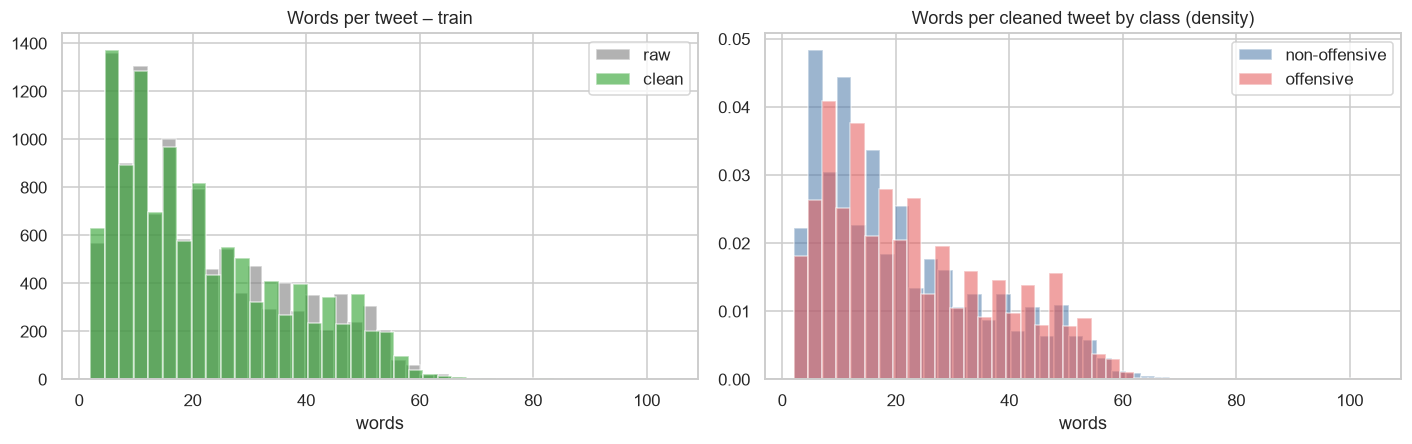

In [37]:
# Number of tokens before / after
for name, d in splits.items():
    d["n_words_raw"]   = d["text"].str.split().str.len()
    d["n_words_clean"] = d["text_clean"].str.split().str.len()

summary_len = pd.DataFrame({
    name: {"avg words (raw)": d["n_words_raw"].mean(),
           "avg words (clean)": d["n_words_clean"].mean(),
           "reduction %": 100 * (1 - d["n_words_clean"].sum() / d["n_words_raw"].sum())}
    for name, d in splits.items()
}).T.round(2)
display(summary_len)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(train_df["n_words_raw"], bins=40, alpha=0.6, label="raw", color="#7f7f7f")
axes[0].hist(train_df["n_words_clean"], bins=40, alpha=0.6, label="clean", color="#2ca02c")
axes[0].set_title("Words per tweet – train"); axes[0].set_xlabel("words"); axes[0].legend()

for lab, name in LABEL_NAMES.items():
    sub = train_df[train_df.label == lab]
    axes[1].hist(sub["n_words_clean"], bins=40, alpha=0.55, density=True, color=COLORS[name], label=name)
axes[1].set_title("Words per cleaned tweet by class (density)"); axes[1].set_xlabel("words"); axes[1].legend()
savefig(fig, "08_length_before_after_cleaning.png")

**Reading.** The number of words barely changes (< 0.5 %): cleaning mostly modifies characters *inside* tokens (case, punctuation, `#`) rather
than deleting whole words. The **shape of the distribution is preserved** and the two classes keep the length profile seen in the EDA. The real
effect of cleaning is on the **vocabulary** (section 8).

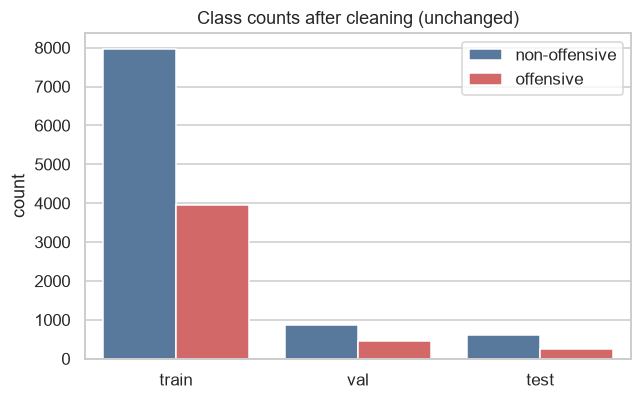

In [38]:
# Visual check of the class distribution: it must be IDENTICAL to the raw data
fig, ax = plt.subplots(figsize=(6, 3.8))
plot = pd.concat([d.assign(split=n) for n, d in splits.items()])
plot["label_name"] = plot["label"].map(LABEL_NAMES)
sns.countplot(x="split", hue="label_name", data=plot, hue_order=["non-offensive", "offensive"], palette=COLORS, ax=ax)
ax.set_title("Class counts after cleaning (unchanged)"); ax.set_xlabel(""); ax.legend(title="")
savefig(fig, "09_class_distribution_after_cleaning.png")

In [39]:
# Random before / after comparison (8 offensive + 8 non-offensive tweets)
sample = pd.concat([
    train_df[train_df.label == 0].sample(8, random_state=7),
    train_df[train_df.label == 1].sample(8, random_state=7),
])
display(sample[["text", "text_clean", "label"]].reset_index(drop=True))

,text,text_clean,label
0,@user While for Republicans there's no difference in % of AGW belief between PhDs and college freshmen because conservatives are more op...,user while for republicans there's no difference in of agw belief between phds and college freshmen because conservatives are more open ...,0
1,@user jimin-ssi i hope you know you are an angel. i love you so much. you are always amazing,user jimin ssi i hope you know you are an angel i love you so much you are always amazing,0
2,@user I still want yo know when you are doing stairway to heaven. 🤣,user i still want yo know when you are doing stairway to heaven,0
3,@user No way! She is!,user no way she is,0
4,@user Eh he is decent I think lol im playing barzal as my first line center over him though,user eh he is decent i think lol im playing barzal as my first line center over him though,0
5,6 people are dead after shooting spree in California ....AND LORD FORBID WE SHOULD TALK ABOUT COMMON SENSE GUN CONTROL MEASURES...OH NO!...,6 people are dead after shooting spree in california and lord forbid we should talk about common sense gun control measures oh no,0
6,"@user Doesn't ALTERNATIVE FACT"""" = FALSEHOOD? #MAGA @user @user @user @user How do """"Alt"""" gov accounts exist? How many account...",user doesn't alternative fact falsehood maga user user user user how do alt gov accounts exist how many accounts illegal subverting will...,0
7,@user Don’t 😂😂😂😂😂,user don't,0
8,@user Go out like Seinfeld and cancel the series while it's hot! Jk don't you fucking dare. This better have a 50 issue plan.,user go out like seinfeld and cancel the series while it's hot jk don't you fucking dare this better have a 50 issue plan,1
9,@user @user @user Please take John Harwood's pen away. He is incapable of unbiased reporting.,user user user please take john harwood's pen away he is incapable of unbiased reporting,1


<a id="7"></a>
## 7. Impact of each cleaning rule
How many tweets does each rule actually change? This quantifies the decisions of section 3 and shows examples for each rule.

,tweets_affected,% of train
upper-case letters,11310,94.9
@mention,11058,92.8
punctuation / symbol removed,9962,83.6
contraction / apostrophe (kept),3817,32.0
emoji / non-ASCII removed,2975,25.0
#hashtag,1727,14.5
HTML entity (&amp; ...),487,4.1
emphasis *word* (removed),70,0.6
masked profanity f*** (kept),30,0.3
URL,0,0.0


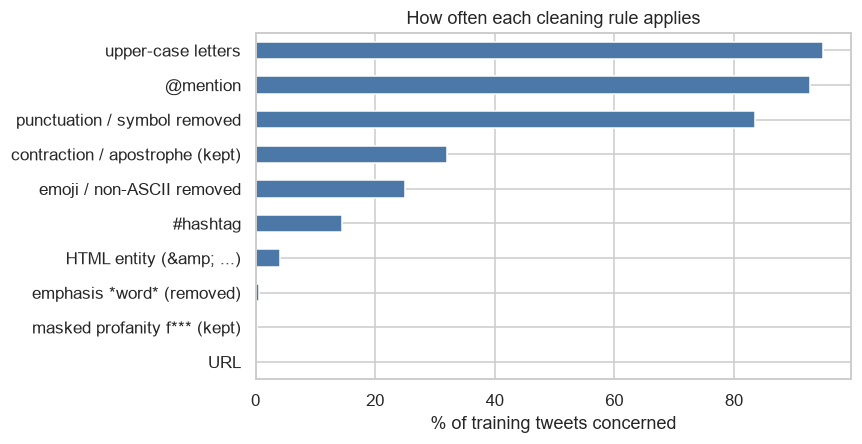

In [40]:
raw = train_df["text"]
rules = {
    "HTML entity (&amp; ...)":          raw.str.contains(r"&\w+;", regex=True),
    "URL":                              raw.str.contains(r"https?://|www\.", regex=True),
    "@mention":                         raw.str.contains(r"@\w+", regex=True),
    "#hashtag":                         raw.str.contains(r"#\w+", regex=True),
    "contraction / apostrophe (kept)":  raw.str.contains(r"\w['’]\w", regex=True),
    "masked profanity f*** (kept)":     raw.str.contains(r"\w\*{2,}|\w\*\w", regex=True),
    "emphasis *word* (removed)":        raw.str.contains(r"(?:^|\s)\*\w+|\w\*(?:\s|$)", regex=True),
    "punctuation / symbol removed":     raw.str.contains(r"[^\w\s@#'’*]", regex=True),
    "emoji / non-ASCII removed":        raw.apply(lambda t: any(ord(c) > 127 for c in t)),
    "upper-case letters":               raw.str.contains(r"[A-Z]", regex=True),
}
impact = pd.DataFrame({"tweets_affected": {k: int(v.sum()) for k, v in rules.items()}})
impact["% of train"] = (100 * impact["tweets_affected"] / len(raw)).round(1)
display(impact.sort_values("tweets_affected", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
impact["% of train"].sort_values().plot(kind="barh", color="#4C78A8", ax=ax)
ax.set_xlabel("% of training tweets concerned"); ax.set_title("How often each cleaning rule applies")
savefig(fig, "10_cleaning_rule_impact.png")

In [41]:
# One concrete example per rule
def show(rule, n=3):
    sub = train_df[rules[rule]].head(n)[["text", "text_clean"]]
    print(f"\n### {rule}")
    display(sub.reset_index(drop=True))

for r in ["HTML entity (&amp; ...)", "#hashtag", "contraction / apostrophe (kept)", "masked profanity f*** (kept)", "emphasis *word* (removed)", "emoji / non-ASCII removed"]:
    show(r)


### HTML entity (&amp; ...)


,text,text_clean
0,@user Antifa would burn a Conservatives house down and CNN would be there lighting the torches &amp; throwing gas on the flames.,user antifa would burn a conservatives house down and cnn would be there lighting the torches throwing gas on the flames
1,@user All we ever hear from Hillary is beeching &amp; moaning. Dang ! That witch never get tired of complaining!,user all we ever hear from hillary is beeching moaning dang that witch never get tired of complaining
2,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user Thank you for adding me Razor! Pa...,user user user user user user user user user user user user user user user user user thank you for adding me razor patriots if you aren'...



### #hashtag


,text,text_clean
0,@user Your looking more like a plant #maga #walkaway,user your looking more like a plant maga walkaway
1,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer did and set America ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did and set america on t...
2,"@user They cite Jones being banned for violating Twitter's ToS. There are blue checkmarks spewing the same, if not worse, kind of shit. ...",user they cite jones being banned for violating twitter's tos there are blue checkmarks spewing the same if not worse kind of shit if yo...



### contraction / apostrophe (kept)


,text,text_clean
0,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president
1,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could be optic too Who k...,user she has become a parody unto herself she has certainly taken some heat for being such an well idiot could be optic too who know wit...
2,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer did and set America ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did and set america on t...


... (2 outputs left out)


### emphasis *word* (removed)


,text,text_clean
0,@user The lies i keep hearing everyday sigh *INHALES* IM TIRED OF YOU PUTTING YOURSELF DOWN AND IF PPL DONT SEE HOW BEAUTIFUL MY BESTFRI...,user the lies i keep hearing everyday sigh inhales im tired of you putting yourself down and if ppl dont see how beautiful my bestfriend...
1,@user Cough*Nicky Haley*,user cough*nicky haley
2,1. the last minute of this video is absolutely priceless 2. facts: “Obama separated 90k kids and there were no protests” liberals: *sil...,1 the last minute of this video is absolutely priceless 2 facts obama separated 90k kids and there were no protests liberals silence



### emoji / non-ASCII removed


,text,text_clean
0,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president
1,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer did and set America ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did and set america on t...
2,@user Friend ordered 100 pair of Levi’s and then called to cancel! Over Gun control! Wow getting wild!,user friend ordered 100 pair of levi's and then called to cancel over gun control wow getting wild


In [42]:
# Negations must survive the cleaning (they are valuable for offensive/non-offensive decisions)
NEG = r"\b(?:not|no|never|nobody|nothing)\b|n't\b"
for name, d in splits.items():
    b = d["text"].str.lower().str.replace("’", "'").str.contains(NEG, regex=True).mean()
    a = d["text_clean"].str.contains(NEG, regex=True).mean()
    print(f"{name:5s}: tweets with a negation  raw = {100*b:.1f} %   cleaned = {100*a:.1f} %")

train: tweets with a negation  raw = 30.8 %   cleaned = 30.7 %
val  : tweets with a negation  raw = 33.2 %   cleaned = 33.2 %
test : tweets with a negation  raw = 28.3 %   cleaned = 28.3 %


**Reading.** Negations are preserved (the rates before/after are practically identical: 30.8 % → 30.7 % on train). The rules that touch the most tweets are
lowercasing (~95 %), mention replacement (~93 %) and punctuation removal (~84 %) — all low-risk transformations. Genuine masked profanity (`f***`) is very
rare (~0.3 % of tweets), and emphasis asterisks (`*inhales*`) about twice as frequent (0.6 %); URLs are absent.

<a id="8"></a>
## 8. Vocabulary before / after
A good cleaning should **shrink the vocabulary** (fewer sparse features) without losing the offensive vocabulary.

In [43]:
def vocab(series):
    c = Counter()
    for t in series:
        c.update(t.split())
    return c

v_raw   = vocab(train_df["text"])
v_clean = vocab(train_df["text_clean"])

voc = pd.DataFrame({
    "raw": {"distinct tokens": len(v_raw), "hapax (appear once)": sum(1 for c in v_raw.values() if c == 1)},
    "clean": {"distinct tokens": len(v_clean), "hapax (appear once)": sum(1 for c in v_clean.values() if c == 1)},
})
voc["change %"] = (100 * (voc["clean"] / voc["raw"] - 1)).round(1)
display(voc)

print("\nTop 15 tokens – RAW   :", [w for w, _ in v_raw.most_common(15)])
print("Top 15 tokens – CLEAN :", [w for w, _ in v_clean.most_common(15)])

# Offensive words must still be present after cleaning
probe = ["idiot", "stupid", "bitch", "shit", "fuck", "coward", "don't", "not"]
print("\nFrequency of key words after cleaning:", {w: v_clean.get(w, 0) for w in probe})

,raw,clean,change %
distinct tokens,36457,18364,-49.6
hapax (appear once),24562,9796,-60.1



Top 15 tokens – RAW   : ['@user', 'the', 'to', 'is', 'a', 'and', 'of', 'you', 'are', 'I', 'in', 'for', 'that', 'he', 'on']
Top 15 tokens – CLEAN : ['user', 'the', 'is', 'to', 'a', 'you', 'and', 'of', 'are', 'i', 'he', 'in', 'that', 'for', 'she']

Frequency of key words after cleaning: {'idiot': 52, 'stupid': 108, 'bitch': 92, 'shit': 328, 'fuck': 162, 'coward': 19, "don't": 770, 'not': 1493}


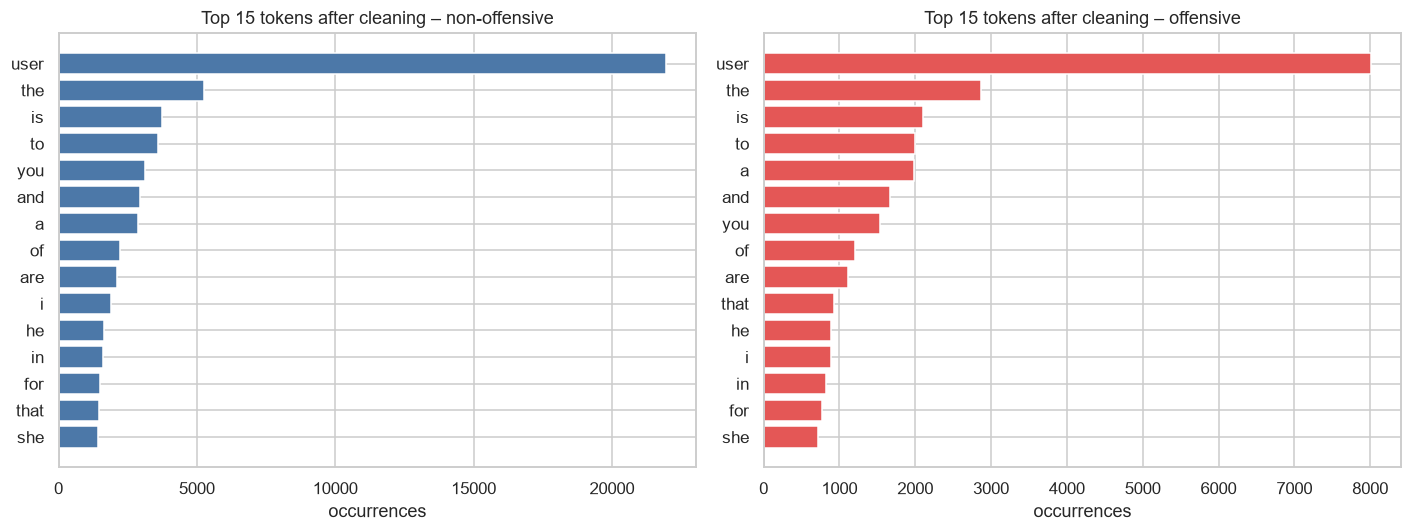

In [44]:
# Top-15 words per class AFTER cleaning (stopwords still present )
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (lab, name) in zip(axes, LABEL_NAMES.items()):
    c = vocab(train_df.loc[train_df.label == lab, "text_clean"])
    words, vals = zip(*c.most_common(15))
    ax.barh(words[::-1], vals[::-1], color=COLORS[name])
    ax.set_title(f"Top 15 tokens after cleaning – {name}"); ax.set_xlabel("occurrences")
savefig(fig, "11_top_tokens_after_cleaning.png")

**Reading.** The vocabulary is **cut roughly in half** (36 457 → 18 364 distinct tokens, −50 %) and the number of words appearing only once drops by
60 %: lowercasing, punctuation and hashtag symbols no longer create variants of the same word. The offensive vocabulary and the negations are intact. The most frequent tokens are now mostly stopwords and `user`: this is expected, since
stopword removal is deliberately left to Youssef's experiments (notebook 03), and TF-IDF will down-weight them anyway.

<a id="9"></a>
## 9. Saving the cleaned datasets
Output files (columns `text`, `text_clean`, `label`) go to `data/processed/`. They are derived data and can be regenerated at any time by running this notebook.

In [45]:
cols = ["text", "text_clean", "label"]
for name, d in splits.items():
    d[cols].to_csv(PROC_DIR / f"{name}_clean.csv", index=False)

# Reload to be sure the saved files are readable and identical to what we have in memory
for name, d in splits.items():
    back = pd.read_csv(PROC_DIR / f"{name}_clean.csv", keep_default_na=False)
    assert len(back) == len(d), f"{name}: row count changed"
    assert (back["label"].values == d["label"].values).all(), f"{name}: labels changed"
    assert (back["text_clean"].values == d["text_clean"].values).all(), f"{name}: text_clean changed"
    print(f"✔ {name}_clean.csv  ->  {back.shape[0]} rows, columns = {list(back.columns)}")

checks_df.to_csv(MET_DIR / "cleaning_checks.csv")
impact.to_csv(MET_DIR / "cleaning_rule_impact.csv")
print("\nFiles in data/processed/:", sorted(p.name for p in PROC_DIR.glob("*.csv")))

✔ train_clean.csv  ->  11916 rows, columns = ['text', 'text_clean', 'label']
✔ val_clean.csv  ->  1324 rows, columns = ['text', 'text_clean', 'label']
✔ test_clean.csv  ->  860 rows, columns = ['text', 'text_clean', 'label']

Files in data/processed/: ['test_clean.csv', 'train_clean.csv', 'val_clean.csv']


> **Tip when re-loading with pandas.** A cleaned tweet can be an empty string; always read the CSV with `keep_default_na=False`
> (or `fillna("")`), otherwise pandas turns empty strings into `NaN` and `TfidfVectorizer` will fail.

<a id="10"></a>
## 10. Conclusions 

### What was done
- Implemented `clean_text()` in `src/preprocessing.py`: lowercase, HTML decoding, URL removal, `@mention → user`, hashtag word kept,
  punctuation and emojis removed, **apostrophes and masked-profanity asterisks preserved**.
- Applied it to the official **train / val / test** splits, creating `text_clean`.
- Verified: unchanged row counts, **no missing values, labels identical to the raw files, class proportions unchanged**, negations preserved.
- Saved `train_clean.csv`, `val_clean.csv`, `test_clean.csv` in `data/processed/`.

### Hand-over 
| Input provided | Used for |
|---|---|
| `data/processed/*_clean.csv` (columns `text`, `text_clean`, `label`) | start from `text_clean` for the stopword / lemmatisation variants |
| Stopwords **not** removed, **no** lemmatisation, **no** balancing | the three variants *clean only* / *+ stopwords* / *+ stopwords + lemmatisation* can be compared fairly |
| Negations kept as `not`, `no`, `don't`, `can't`… | custom stopword list must protect them (including the forms with apostrophe) |

### Rules both of us follow
- Train may be balanced **for experiments only**; validation and test always keep the original distribution.
- Labels are never modified.
- TF-IDF is fitted on **train only**.
- Same splits and same reference model for every comparison; the test set is **not** used to choose techniques.

### Next step
`02_preprocessing_experiments.ipynb`→ compare the variants on the validation set → build the final pipeline together
(`src/final_pipeline.py`) keeping only the transformations that improve the validation F1.